# Consumer Churn Prediction Project

In [2]:
import pandas as pd
df = pd.read_csv("/content/consumer_classification_dataset.csv")
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1425 non-null   float64
 1   Income            1425 non-null   float64
 2   Gender            1425 non-null   object 
 3   Marital_Status    1500 non-null   object 
 4   Credit_Score      1425 non-null   float64
 5   Num_Purchases     1500 non-null   int64  
 6   Membership_Years  1500 non-null   int64  
 7   Device_Used       1500 non-null   object 
 8   Churn             1500 non-null   int64  
dtypes: float64(3), int64(3), object(3)
memory usage: 105.6+ KB


,Age,Income,Credit_Score,Num_Purchases,Membership_Years,Churn
count,1425.000000,1425.000000,1425.000000,1500.000000,1500.000000,1500.000000
mean,43.750175,50446.150664,648.786794,5.078667,7.388667,0.495333
std,15.026126,15320.475325,69.583710,2.260653,3.974603,0.500145
min,18.000000,-826.421240,390.384237,0.000000,1.000000,0.000000
25%,31.000000,40557.251779,601.996211,3.000000,4.000000,0.000000
50%,44.000000,50671.503006,650.015506,5.000000,7.000000,0.000000
75%,56.000000,60994.627689,694.954684,6.000000,11.000000,1.000000
max,69.000000,98819.709397,906.039126,16.000000,14.000000,1.000000


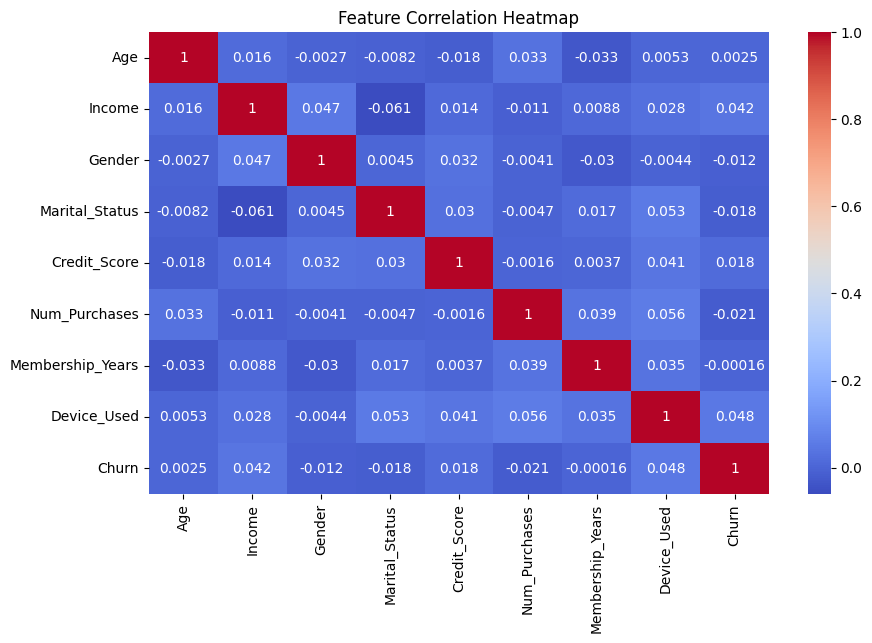

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
eda_df = df.dropna()
eda_encoded = eda_df.copy()
eda_encoded["Gender"] = eda_encoded["Gender"].astype("category").cat.codes
eda_encoded["Marital_Status"] = eda_encoded["Marital_Status"].astype("category").cat.codes
eda_encoded["Device_Used"] = eda_encoded["Device_Used"].astype("category").cat.codes
plt.figure(figsize=(10, 6))
sns.heatmap(eda_encoded.corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

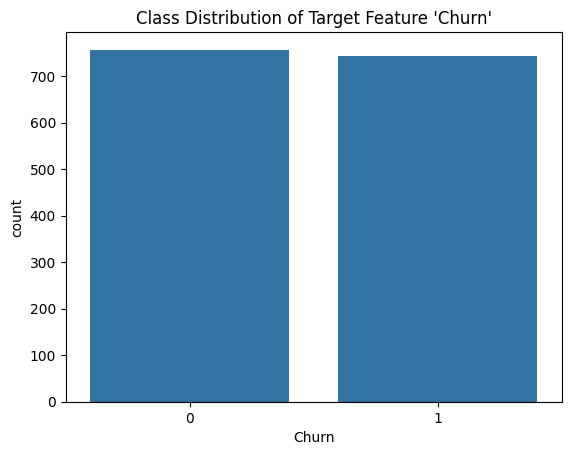

In [4]:
sns.countplot(data=df, x='Churn')
plt.title("Class Distribution of Target Feature 'Churn'")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

data = df.copy()
num_cols = ['Age', 'Income', 'Credit_Score']
imputer = SimpleImputer(strategy='mean')
data[num_cols] = imputer.fit_transform(data[num_cols])
cat_cols = ['Gender', 'Marital_Status', 'Device_Used']
encoders = {col: LabelEncoder() for col in cat_cols}
for col in cat_cols:
    data[col] = encoders[col].fit_transform(data[col])
X = data.drop('Churn', axis=1)
y = data['Churn']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42, stratify=y)

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000)
}
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Confusion Matrix": confusion_matrix(y_test, y_pred),
        "Classification Report": classification_report(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob) if y_prob is not None else "N/A"
    }
results

/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


{'Logistic Regression': {'Accuracy': 0.4911111111111111,
  'Confusion Matrix': array([[128,  99],
         [130,  93]]),
  'Classification Report': '              precision    recall  f1-score   support\n\n           0       0.50      0.56      0.53       227\n           1       0.48      0.42      0.45       223\n\n    accuracy                           0.49       450\n   macro avg       0.49      0.49      0.49       450\nweighted avg       0.49      0.49      0.49       450\n',
  'ROC AUC': np.float64(0.4967108512277513)},
 'Decision Tree': {'Accuracy': 0.5133333333333333,
  'Confusion Matrix': array([[119, 108],
         [111, 112]]),
  'Classification Report': '              precision    recall  f1-score   support\n\n           0       0.52      0.52      0.52       227\n           1       0.51      0.50      0.51       223\n\n    accuracy                           0.51       450\n   macro avg       0.51      0.51      0.51       450\nweighted avg       0.51      0.51      0.51   

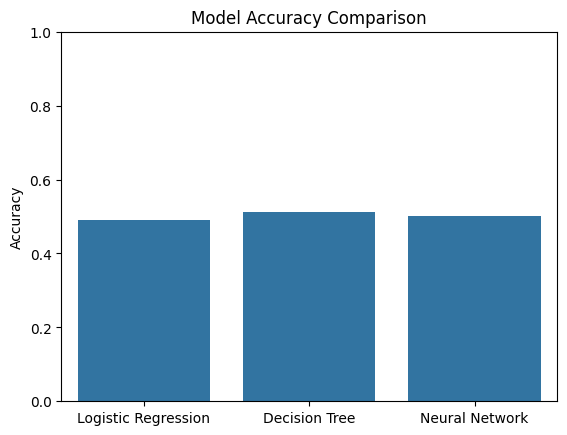

In [7]:
model_names = list(results.keys())
accuracies = [results[m]["Accuracy"] for m in model_names]
sns.barplot(x=model_names, y=accuracies)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

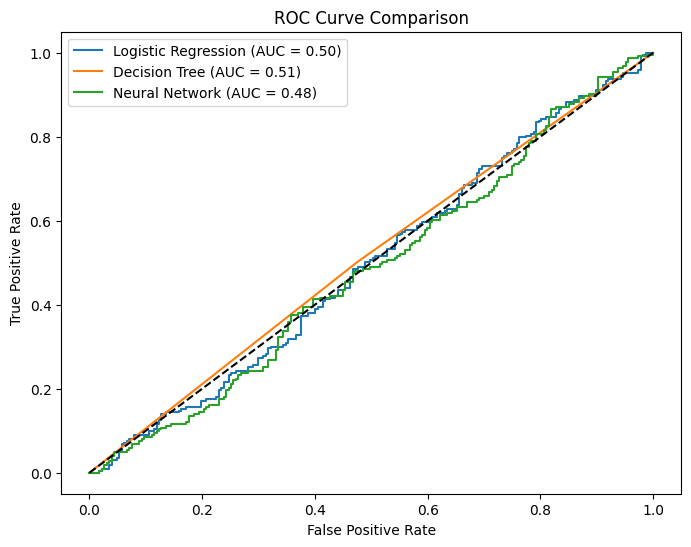

In [8]:
plt.figure(figsize=(8, 6))
for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['ROC AUC']:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()